<a href="https://colab.research.google.com/github/Renyambar/Reny_MachineLearning/blob/main/JS10/JS10_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1. Import LIbrary


#Tugas Lab
* Lakukan klasifikasi pada data MNIST dengan menggunakan model ANN

* Anda diperbolehkan melakukan eksplorasi terhadap,

1. Metode pra pengolahan
2. Pemilihan fitur

3. Arsitektur ANN

4. Fungsi Aktivasi

* ANN diimplementasikan dengan menggunakan tensorflow.



##1.Import library

In [1]:

# Import library utama
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

# Import preprocessing dan evaluasi
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Import TensorFlow Keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Pengaturan random seed
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
GPU Available: []


##2. Memuat dataset MNIST

In [2]:

# Memuat dataset MNIST dari TensorFlow
from tensorflow.keras.datasets import mnist

(X_train_original, y_train_original), (X_test_original, y_test) = mnist.load_data()

print("Dataset berhasil dimuat!")
print("Training images:", X_train_original.shape)
print("Training labels:", y_train_original.shape)
print("Testing images:", X_test_original.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dataset berhasil dimuat!
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [3]:

# Informasi dataset
print("Jumlah data training:", len(X_train_original))
print("Jumlah data testing:", len(X_test_original))

print("Ukuran citra:", X_train_original.shape[1:])
print("Jumlah kelas:", len(np.unique(y_train_original)))
print("Label kelas:", np.unique(y_train_original))

print("Nilai piksel minimum:", X_train_original.min())
print("Nilai piksel maksimum:", X_train_original.max())


Jumlah data training: 60000
Jumlah data testing: 10000
Ukuran citra: (28, 28)
Jumlah kelas: 10
Label kelas: [0 1 2 3 4 5 6 7 8 9]
Nilai piksel minimum: 0
Nilai piksel maksimum: 255


##3. Eksplorasi dan visualisasi dataset

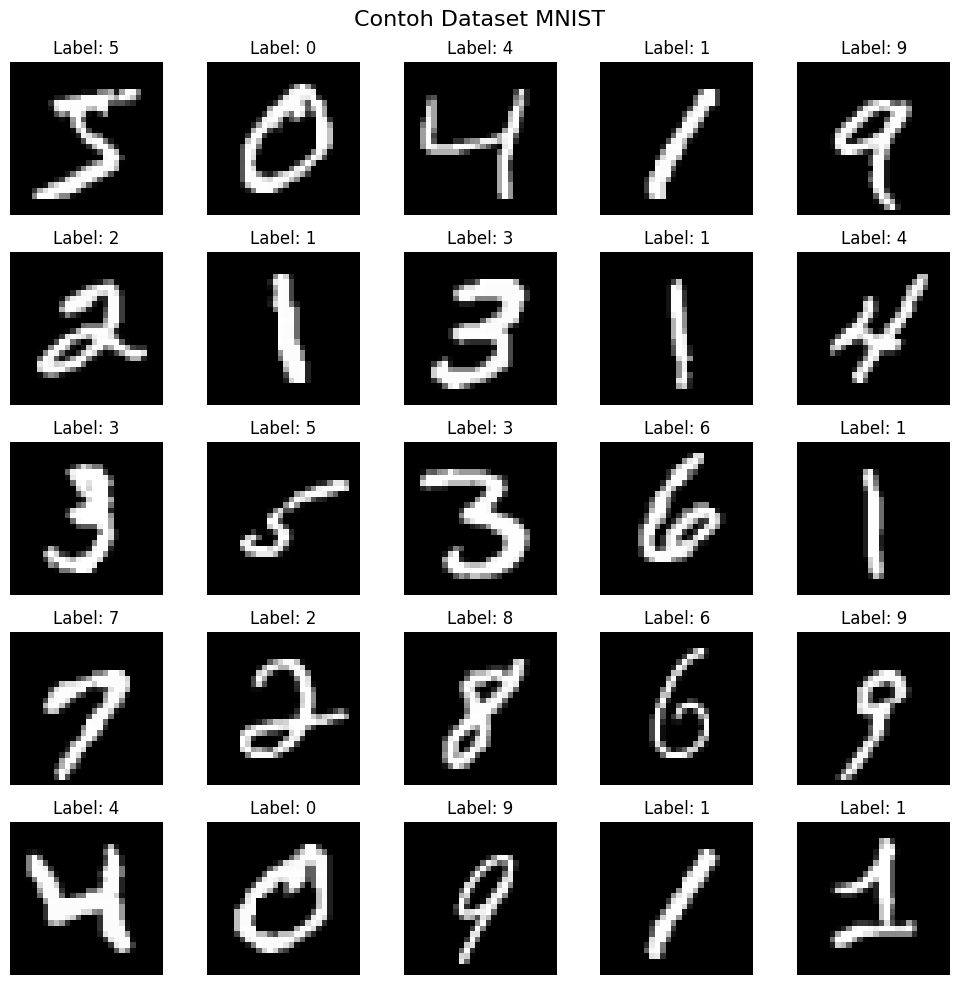

In [4]:

# Menampilkan 25 sampel citra MNIST
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_original[i], cmap='gray')
    plt.title(f"Label: {y_train_original[i]}")
    plt.axis('off')

plt.suptitle("Contoh Dataset MNIST", fontsize=16)
plt.tight_layout()
plt.show()


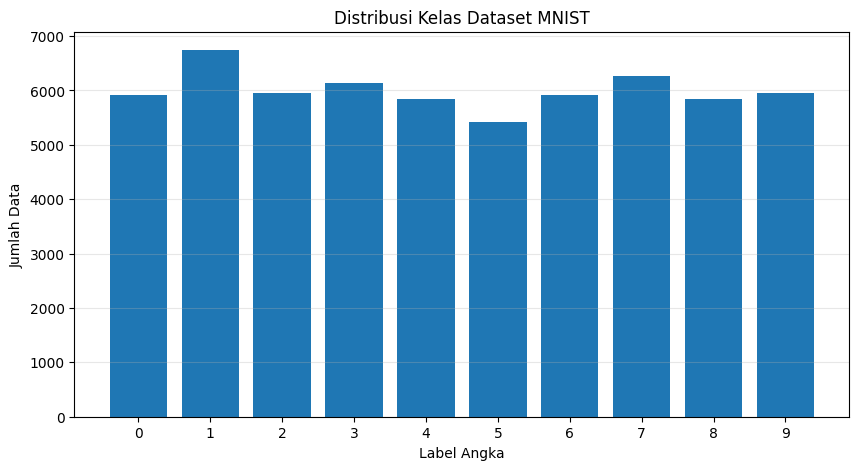

,Label,Jumlah Data
0,0,5923
1,1,6742
2,2,5958
3,3,6131
4,4,5842
5,5,5421
6,6,5918
7,7,6265
8,8,5851
9,9,5949


In [5]:

# Menghitung distribusi label
unique, counts = np.unique(y_train_original, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(unique, counts)

plt.title("Distribusi Kelas Dataset MNIST")
plt.xlabel("Label Angka")
plt.ylabel("Jumlah Data")
plt.xticks(unique)
plt.grid(axis='y', alpha=0.3)

plt.show()

# Tabel distribusi
distribution = pd.DataFrame({
    'Label': unique,
    'Jumlah Data': counts
})

display(distribution)


##4. Preprocessing data
Preprocessing dilakukan melalui beberapa tahapan:

1. Mengubah citra berukuran 28 × 28 menjadi vektor 784 fitur.
2. Melakukan normalisasi nilai piksel dari rentang 0–255 menjadi 0–1.
3. Membagi data training menjadi training dan validation.
4. Mempertahankan data testing untuk evaluasi akhir.

In [6]:

# Mengubah citra 28x28 menjadi vektor 784 fitur
X_train_flat = X_train_original.reshape(
    X_train_original.shape[0], -1
)

X_test_flat = X_test_original.reshape(
    X_test_original.shape[0], -1
)

# Normalisasi nilai piksel
X_train_scaled = X_train_flat.astype('float32') / 255.0
X_test_scaled = X_test_flat.astype('float32') / 255.0

print("Shape training:", X_train_scaled.shape)
print("Shape testing:", X_test_scaled.shape)

print("Nilai minimum:", X_train_scaled.min())
print("Nilai maksimum:", X_train_scaled.max())


Shape training: (60000, 784)
Shape testing: (10000, 784)
Nilai minimum: 0.0
Nilai maksimum: 1.0


In [7]:

# Membagi training menjadi 80% training dan 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled,
    y_train_original,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_original
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data validation:", X_val.shape[0])
print("Jumlah data testing:", X_test_scaled.shape[0])


Jumlah data training: 48000
Jumlah data validation: 12000
Jumlah data testing: 10000


##5. Eksplorasi pemilihan fitur (Feature Selection)
Setiap citra MNIST memiliki 784 fitur piksel.

Pada eksperimen ini digunakan metode SelectKBest dengan ANOVA F-test untuk memilih fitur yang memiliki hubungan statistik paling kuat dengan label kelas.

Jumlah fitur yang dipilih adalah 400 fitur dari total 784 fitur.


In [8]:
# Membuat feature selector
selector = SelectKBest(
    score_func=f_classif,
    k=400
)

# Fit hanya pada training
X_train_selected = selector.fit_transform(X_train, y_train)

# Transform validation dan testing
X_val_selected = selector.transform(X_val)
X_test_selected = selector.transform(X_test_scaled)

print("Fitur awal:", X_train.shape[1])
print("Fitur terpilih:", X_train_selected.shape[1])

print("Training selected:", X_train_selected.shape)
print("Validation selected:", X_val_selected.shape)
print("Testing selected:", X_test_selected.shape)


Fitur awal: 784
Fitur terpilih: 400
Training selected: (48000, 400)
Validation selected: (12000, 400)
Testing selected: (10000, 400)


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  0   1   2   3   4   5   6   7   8   9  10  11  16  17  18  19  20  21
  22  23  24  25  26  27  28  29  30  31  32  52  53  54  55  56  57  58
  82  83  84  85 111 112 140 141 168 196 448 476 532 560 644 645 671 672
 673 699 700 701 727 728 729 730 754 755 756 757 758 759 780 781 782 783] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


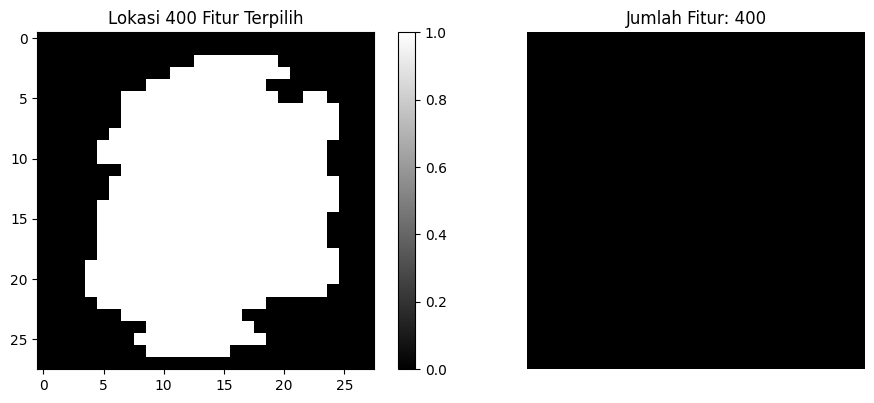

In [10]:

# Menampilkan posisi fitur yang terpilih
selected_indices = selector.get_support(indices=True)

feature_mask = np.zeros(784)
feature_mask[selected_indices] = 1

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(feature_mask.reshape(28, 28), cmap='gray')
plt.title("Lokasi 400 Fitur Terpilih")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(
    X_train_selected[0].shape[0] * np.ones((1, 1)),
    cmap='gray'
)
plt.title("Jumlah Fitur: 400")
plt.axis('off')

plt.tight_layout()
plt.show()

##6. Membangun model Artificial Neural Network

In [11]:

def build_ann(
    input_dim,
    hidden_layers=(128,),
    activation='relu',
    dropout_rate=0.0,
    learning_rate=0.001
):
    model = Sequential()

    model.add(Input(shape=(input_dim,)))

    for units in hidden_layers:
        model.add(Dense(
            units,
            activation=activation
        ))

        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    # Output layer untuk 10 kelas
    model.add(Dense(
        10,
        activation='softmax'
    ))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# Contoh membuat model ANN
model_example = build_ann(
    input_dim=784,
    hidden_layers=(128,),
    activation='relu'
)

model_example.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

##7. Eksperimen fungsi aktivasi

Eksperimen ini bertujuan membandingkan pengaruh fungsi aktivasi terhadap performa ANN.

Fungsi aktivasi yang dibandingkan:

1. ReLU
2. Sigmoid
3. Tanh

In [12]:

EPOCHS = 10
BATCH_SIZE = 128

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

activation_results = []
activation_histories = {}
activation_models = {}

activation_functions = [
    'relu',
    'sigmoid',
    'tanh'
]

print("Activation functions:", activation_functions)


Activation functions: ['relu', 'sigmoid', 'tanh']


In [13]:

for activation in activation_functions:

    print("\n" + "="*50)
    print("Training dengan aktivasi:", activation)
    print("="*50)

    model = build_ann(
        input_dim=784,
        hidden_layers=(128,),
        activation=activation
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=1
    )

    training_time = time.time() - start_time

    # Evaluasi validation
    val_loss, val_accuracy = model.evaluate(
        X_val, y_val, verbose=0
    )

    activation_results.append({
        'Activation': activation,
        'Validation Accuracy': val_accuracy,
        'Validation Loss': val_loss,
        'Training Time (s)': training_time
    })

    activation_histories[activation] = history
    activation_models[activation] = model


activation_df = pd.DataFrame(activation_results)

display(
    activation_df.sort_values(
        by='Validation Accuracy',
        ascending=False
    )
)



Training dengan aktivasi: relu
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8942 - loss: 0.3945 - val_accuracy: 0.9296 - val_loss: 0.2436
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9474 - loss: 0.1837 - val_accuracy: 0.9479 - val_loss: 0.1798
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9627 - loss: 0.1317 - val_accuracy: 0.9588 - val_loss: 0.1464
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9706 - loss: 0.1019 - val_accuracy: 0.9633 - val_loss: 0.1261
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9770 - loss: 0.0818 - val_accuracy: 0.9668 - val_loss: 0.1120
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9812 - loss: 0.0672 - val_accuracy: 0.9693 - val_loss: 0.1035
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9846 - loss: 0.0558 - val_accuracy: 0.9709 - val_loss: 0.0977
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9879 -

,Activation,Validation Accuracy,Validation Loss,Training Time (s)
0,relu,0.972250,0.091593,29.373374
2,tanh,0.922000,0.265427,7.859882
1,sigmoid,0.908083,0.346685,10.638412


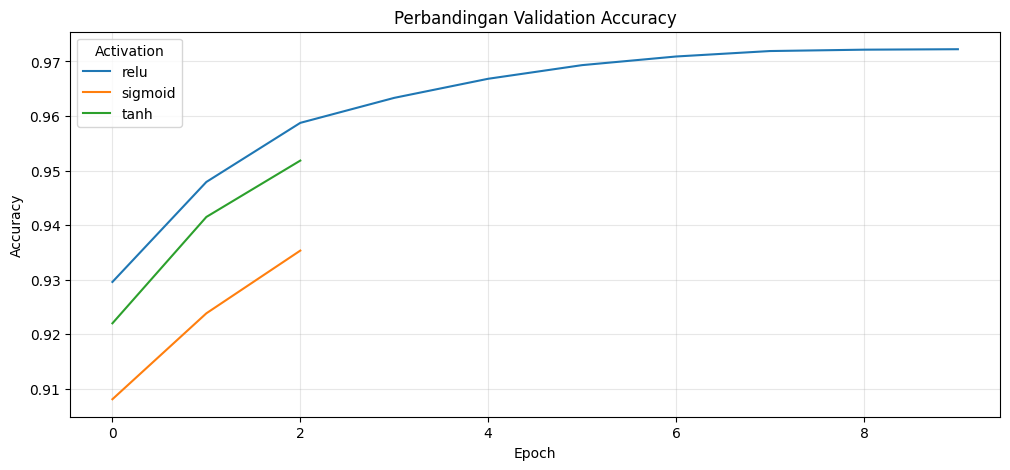

In [14]:

plt.figure(figsize=(12, 5))

for activation, history in activation_histories.items():
    plt.plot(
        history.history['val_accuracy'],
        label=activation
    )

plt.title("Perbandingan Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(title="Activation")
plt.grid(alpha=0.3)
plt.show()


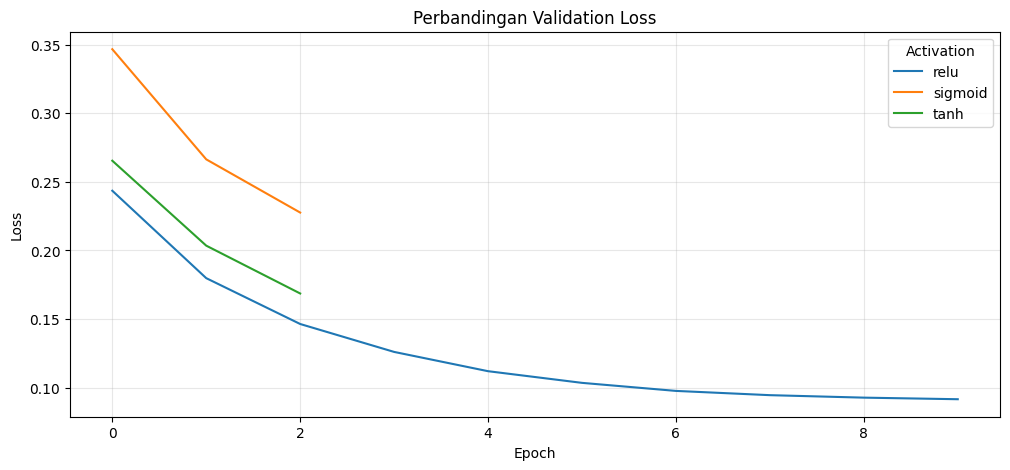

In [15]:

plt.figure(figsize=(12, 5))

for activation, history in activation_histories.items():
    plt.plot(
        history.history['val_loss'],
        label=activation
    )

plt.title("Perbandingan Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(title="Activation")
plt.grid(alpha=0.3)
plt.show()


##8. Eksperimen arsitektur ANN
Pada eksperimen ini dilakukan perbandingan jumlah hidden layer dan jumlah neuron.

Arsitektur yang digunakan:

- Model 1: 1 hidden layer dengan 64 neuron.
- Model 2: 1 hidden layer dengan 128 neuron.
- Model 3: 2 hidden layer dengan 128 dan 64 neuron.
- Model 4: 3 hidden layer dengan 256, 128, dan 64 neuron.

Seluruh model menggunakan fungsi aktivasi ReLU dan optimizer Adam.

In [16]:

architectures = {
    'ANN_64': (64,),
    'ANN_128': (128,),
    'ANN_128_64': (128, 64),
    'ANN_256_128_64': (256, 128, 64)
}

architecture_results = []
architecture_histories = {}
architecture_models = {}


In [17]:

for name, layers in architectures.items():

    print("\n" + "="*50)
    print("Training arsitektur:", name, layers)
    print("="*50)

    model = build_ann(
        input_dim=784,
        hidden_layers=layers,
        activation='relu'
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=1
    )

    training_time = time.time() - start_time

    val_loss, val_accuracy = model.evaluate(
        X_val, y_val, verbose=0
    )

    architecture_results.append({
        'Architecture': name,
        'Hidden Layers': len(layers),
        'Neurons': str(layers),
        'Validation Accuracy': val_accuracy,
        'Validation Loss': val_loss,
        'Training Time (s)': training_time
    })

    architecture_histories[name] = history
    architecture_models[name] = model


architecture_df = pd.DataFrame(architecture_results)

display(
    architecture_df.sort_values(
        by='Validation Accuracy',
        ascending=False
    )
)



Training arsitektur: ANN_64 (64,)
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8741 - loss: 0.4676 - val_accuracy: 0.9222 - val_loss: 0.2741
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9349 - loss: 0.2266 - val_accuracy: 0.9402 - val_loss: 0.2124
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9488 - loss: 0.1752 - val_accuracy: 0.9490 - val_loss: 0.1800

Training arsitektur: ANN_128 (128,)
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8942 - loss: 0.3932 - val_accuracy: 0.9312 - val_loss: 0.2350
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9473 - loss: 0.1827 - val_accuracy: 0.9517 - val_loss: 0.1691
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9625 - loss: 0.1317 - val_accuracy: 0.9596 - val_loss: 0.1379

Training arsitektur: ANN_128_64 (128, 64)
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8982 - loss: 0.3684 - val_accuracy: 0.9413 - val_lo

,Architecture,Hidden Layers,Neurons,Validation Accuracy,Validation Loss,Training Time (s)
3,ANN_256_128_64,3,"(256, 128, 64)",0.952833,0.158770,13.508998
2,ANN_128_64,2,"(128, 64)",0.941250,0.198131,8.629486
1,ANN_128,1,"(128,)",0.931167,0.235014,9.169858
0,ANN_64,1,"(64,)",0.922167,0.274142,6.484430


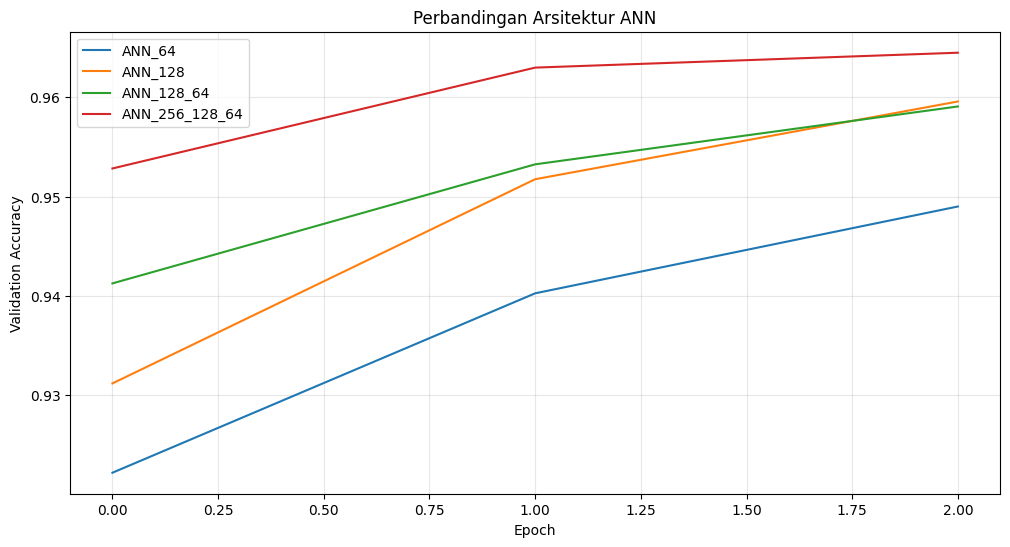

In [18]:

plt.figure(figsize=(12, 6))

for name, history in architecture_histories.items():
    plt.plot(
        history.history['val_accuracy'],
        label=name
    )

plt.title("Perbandingan Arsitektur ANN")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


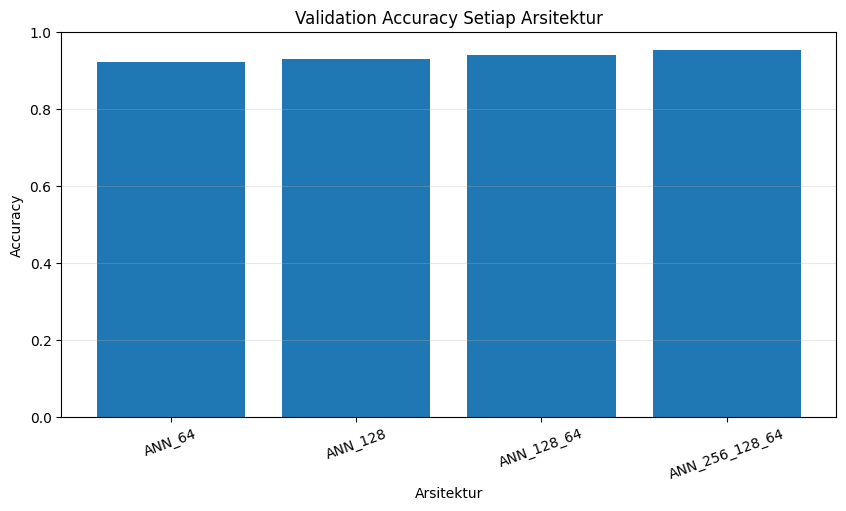

In [19]:

plt.figure(figsize=(10, 5))

plt.bar(
    architecture_df['Architecture'],
    architecture_df['Validation Accuracy']
)

plt.title("Validation Accuracy Setiap Arsitektur")
plt.xlabel("Arsitektur")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.show()


##9. Eksperimen feature selection
Eksperimen ini bertujuan mengetahui apakah pengurangan jumlah fitur dapat memengaruhi performa ANN.

Dua konfigurasi akan dibandingkan:

1. ANN menggunakan seluruh 784 fitur piksel.
2. ANN menggunakan 400 fitur hasil SelectKBest.

Kedua model menggunakan arsitektur yang sama, yaitu 128 neuron pada hidden layer dan aktivasi ReLU.

In [20]:

selected_feature_model = build_ann(
    input_dim=400,
    hidden_layers=(128,),
    activation='relu'
)

start_time = time.time()

selected_feature_history = selected_feature_model.fit(
    X_train_selected,
    y_train,
    validation_data=(X_val_selected, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

selected_feature_training_time = time.time() - start_time

selected_val_loss, selected_val_accuracy = (
    selected_feature_model.evaluate(
        X_val_selected,
        y_val,
        verbose=0
    )
)

print("Validation Accuracy:", selected_val_accuracy)
print("Validation Loss:", selected_val_loss)
print("Training Time:", selected_feature_training_time)


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8866 - loss: 0.4118 - val_accuracy: 0.9288 - val_loss: 0.2473
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9455 - loss: 0.1902 - val_accuracy: 0.9486 - val_loss: 0.1803
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9607 - loss: 0.1383 - val_accuracy: 0.9573 - val_loss: 0.1470
Validation Accuracy: 0.9288333058357239
Validation Loss: 0.2473142445087433
Training Time: 5.998126268386841


In [21]:
feature_comparison = pd.DataFrame([
    {
        'Feature Method': 'All Features (784)',
        'Validation Accuracy': activation_results[
            0
        ]['Validation Accuracy']
    },
    {
        'Feature Method': 'Selected Features (400)',
        'Validation Accuracy': selected_val_accuracy
    }
])

display(feature_comparison)

,Feature Method,Validation Accuracy
0,All Features (784),0.972250
1,Selected Features (400),0.928833


##10. Membandingkan seluruh hasil eksperimen

In [22]:

# Menggabungkan hasil eksperimen aktivasi dan arsitektur

all_results = []

for _, row in activation_df.iterrows():
    all_results.append({
        'Experiment': 'Activation',
        'Configuration': row['Activation'],
        'Validation Accuracy': row['Validation Accuracy'],
        'Validation Loss': row['Validation Loss'],
        'Training Time (s)': row['Training Time (s)']
    })

for _, row in architecture_df.iterrows():
    all_results.append({
        'Experiment': 'Architecture',
        'Configuration': row['Architecture'],
        'Validation Accuracy': row['Validation Accuracy'],
        'Validation Loss': row['Validation Loss'],
        'Training Time (s)': row['Training Time (s)']
    })

all_results.append({
    'Experiment': 'Feature Selection',
    'Configuration': '400 Selected Features',
    'Validation Accuracy': selected_val_accuracy,
    'Validation Loss': selected_val_loss,
    'Training Time (s)': selected_feature_training_time
})

all_results_df = pd.DataFrame(all_results)

all_results_df = all_results_df.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

display(all_results_df)


,Experiment,Configuration,Validation Accuracy,Validation Loss,Training Time (s)
0,Activation,relu,0.972250,0.091593,29.373374
1,Architecture,ANN_256_128_64,0.952833,0.158770,13.508998
2,Architecture,ANN_128_64,0.941250,0.198131,8.629486
3,Architecture,ANN_128,0.931167,0.235014,9.169858
4,Feature Selection,400 Selected Features,0.928833,0.247314,5.998126
5,Architecture,ANN_64,0.922167,0.274142,6.484430
6,Activation,tanh,0.922000,0.265427,7.859882
7,Activation,sigmoid,0.908083,0.346685,10.638412


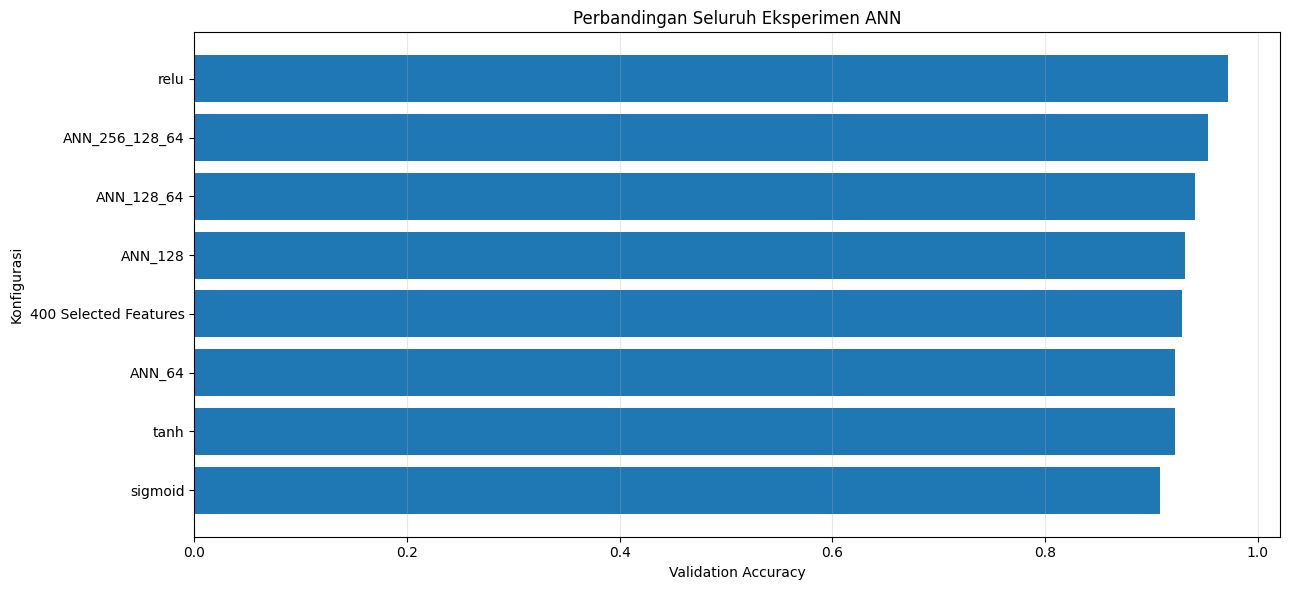

In [23]:

plt.figure(figsize=(13, 6))

plt.barh(
    all_results_df['Configuration'],
    all_results_df['Validation Accuracy']
)

plt.title("Perbandingan Seluruh Eksperimen ANN")
plt.xlabel("Validation Accuracy")
plt.ylabel("Konfigurasi")
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


##11. Best Model Selection

In [24]:

# Menyimpan semua kandidat model
model_candidates = []

for activation, model in activation_models.items():
    _, acc = model.evaluate(X_val, y_val, verbose=0)

    model_candidates.append({
        'name': f'Activation_{activation}',
        'model': model,
        'input_type': 'all',
        'accuracy': acc
    })

for name, model in architecture_models.items():
    _, acc = model.evaluate(X_val, y_val, verbose=0)

    model_candidates.append({
        'name': name,
        'model': model,
        'input_type': 'all',
        'accuracy': acc
    })

model_candidates.append({
    'name': 'Feature_Selection_400',
    'model': selected_feature_model,
    'input_type': 'selected',
    'accuracy': selected_val_accuracy
})

# Memilih berdasarkan validation accuracy
best_candidate = max(
    model_candidates,
    key=lambda x: x['accuracy']
)

best_model = best_candidate['model']
best_model_name = best_candidate['name']
best_input_type = best_candidate['input_type']

print("MODEL TERBAIK")
print("Nama:", best_model_name)
print("Input Type:", best_input_type)
print("Validation Accuracy:", best_candidate['accuracy'])

best_model.summary()


MODEL TERBAIK
Nama: Activation_relu
Input Type: all
Validation Accuracy: 0.9722499847412109


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

##12. Evaluasi model menggunakan data testing

In [25]:
# Menentukan input sesuai model terpilih
if best_input_type == 'selected':
    X_test_best = X_test_selected
else:
    X_test_best = X_test_scaled

# Evaluasi model
test_loss, test_accuracy = best_model.evaluate(
    X_test_best,
    y_test,
    verbose=1
)

print("\nHASIL EVALUASI MODEL")
print("Best Model:", best_model_name)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9766 - loss: 0.0780

HASIL EVALUASI MODEL
Best Model: Activation_relu
Test Loss: 0.07795567065477371
Test Accuracy: 0.9765999913215637
Test Accuracy (%): 97.65999913215637


In [26]:
# Melakukan prediksi
y_probability = best_model.predict(
    X_test_best,
    verbose=1
)

# Mengambil kelas dengan probabilitas tertinggi
y_pred = np.argmax(y_probability, axis=1)

print("Jumlah prediksi:", len(y_pred))
print("Contoh hasil prediksi:", y_pred[:20])
print("Label sebenarnya:", y_test[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Jumlah prediksi: 10000
Contoh hasil prediksi: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Label sebenarnya: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [27]:
# Classification report
report = classification_report(
    y_test,
    y_pred,
    digits=4,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print(report)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9857    0.9857    0.9857       980
           1     0.9868    0.9903    0.9886      1135
           2     0.9712    0.9806    0.9759      1032
           3     0.9782    0.9752    0.9767      1010
           4     0.9747    0.9796    0.9771       982
           5     0.9774    0.9709    0.9741       892
           6     0.9821    0.9718    0.9769       958
           7     0.9663    0.9767    0.9715      1028
           8     0.9722    0.9702    0.9712       974
           9     0.9710    0.9623    0.9667      1009

    accuracy                         0.9766     10000
   macro avg     0.9766    0.9763    0.9764     10000
weighted avg     0.9766    0.9766    0.9766     10000



In [28]:

# Menghitung metrik keseluruhan
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro',
    zero_division=0
)

evaluation_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision (Macro)',
        'Recall (Macro)',
        'F1-Score (Macro)',
        'Test Loss'
    ],
    'Value': [
        accuracy,
        precision,
        recall,
        f1,
        test_loss
    ]
})

display(evaluation_results)


,Metric,Value
0,Accuracy,0.976600
1,Precision (Macro),0.976561
2,Recall (Macro),0.976341
3,F1-Score (Macro),0.976439
4,Test Loss,0.077956


##13. Confusion matrix

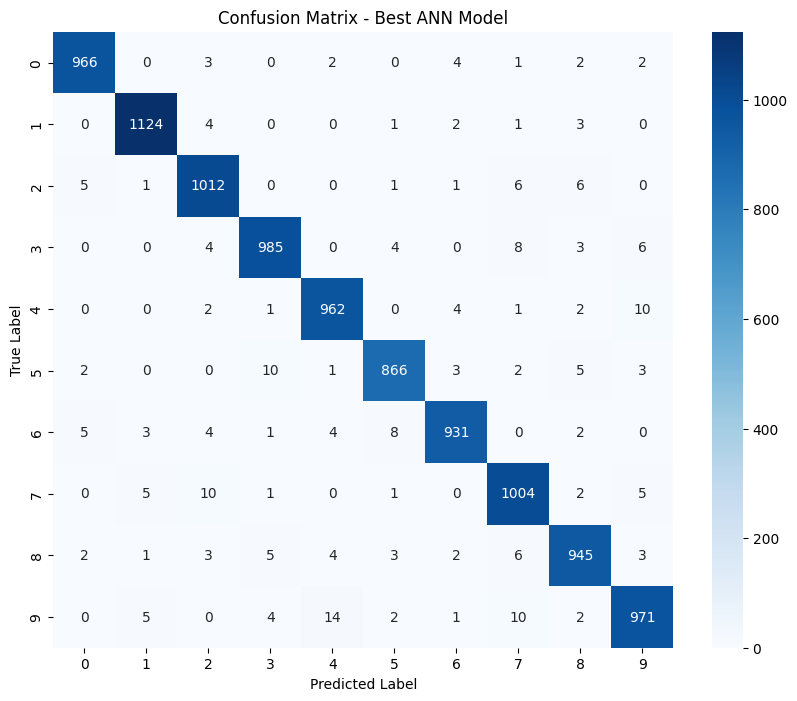

In [29]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix - Best ANN Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


##14. Visualisasi hasil prediksi

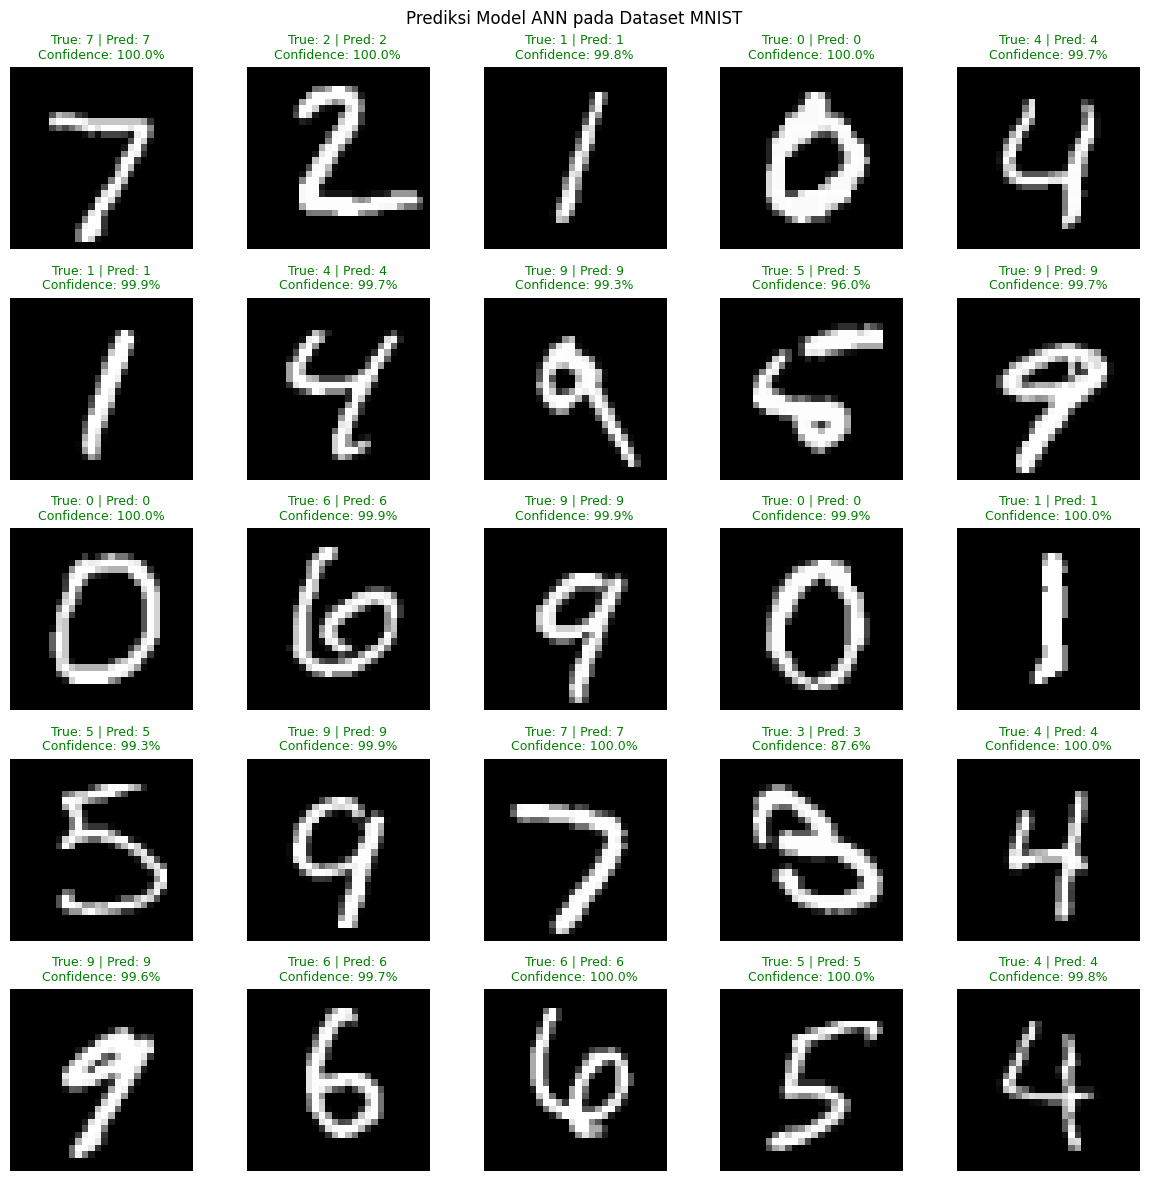

In [30]:

plt.figure(figsize=(12, 12))

for i in range(25):
    plt.subplot(5, 5, i + 1)

    plt.imshow(X_test_original[i], cmap='gray')

    true_label = y_test[i]
    predicted_label = y_pred[i]
    confidence = np.max(y_probability[i]) * 100

    color = 'green' if true_label == predicted_label else 'red'

    plt.title(
        f"True: {true_label} | Pred: {predicted_label}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.suptitle("Prediksi Model ANN pada Dataset MNIST")
plt.tight_layout()
plt.show()


##15. Analisis kesalahan prediksi

Jumlah prediksi salah: 234
Jumlah prediksi benar: 9766


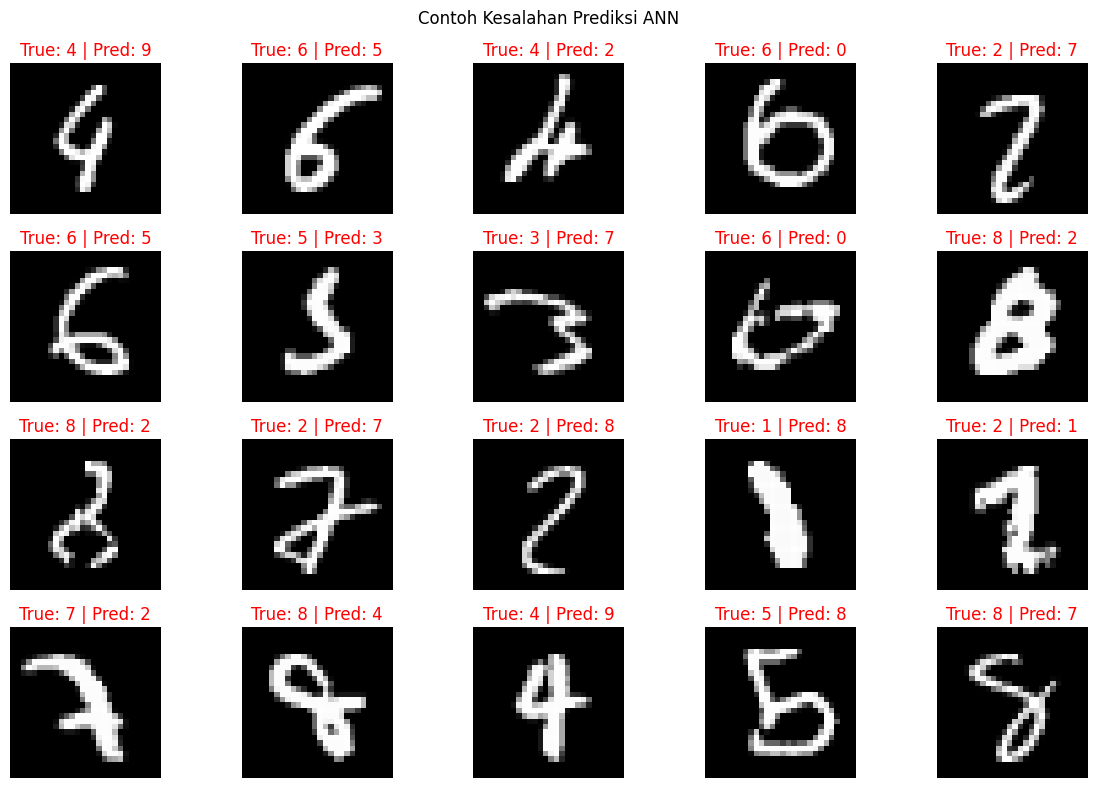

In [31]:
# Mengambil indeks data yang salah diprediksi
wrong_indices = np.where(y_pred != y_test)[0]

print("Jumlah prediksi salah:", len(wrong_indices))
print("Jumlah prediksi benar:", len(y_test) - len(wrong_indices))

plt.figure(figsize=(12, 8))

for i, idx in enumerate(wrong_indices[:20]):
    plt.subplot(4, 5, i + 1)

    plt.imshow(X_test_original[idx], cmap='gray')

    plt.title(
        f"True: {y_test[idx]} | Pred: {y_pred[idx]}",
        color='red'
    )

    plt.axis('off')

plt.suptitle("Contoh Kesalahan Prediksi ANN")
plt.tight_layout()
plt.show()


##16. Kesimpulan eksperimen

In [32]:

print("=" * 55)
print("RINGKASAN HASIL TUGAS LAB JS10 - ANN")
print("=" * 55)

print("\n1. DATASET")
print("Dataset: MNIST")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test_scaled))
print("Jumlah kelas: 10")

print("\n2. FEATURE SELECTION")
print("Fitur awal: 784")
print("Fitur terpilih:", X_train_selected.shape[1])
print("Validation Accuracy:", round(selected_val_accuracy, 4))

print("\n3. MODEL TERBAIK")
print("Nama:", best_model_name)
print("Validation Accuracy:", round(best_candidate['accuracy'], 4))

print("\n4. HASIL TESTING")
print("Accuracy:", round(accuracy, 4))
print("Precision Macro:", round(precision, 4))
print("Recall Macro:", round(recall, 4))
print("F1-Score Macro:", round(f1, 4))
print("Test Loss:", round(test_loss, 4))

print("\n5. KESIMPULAN")
print(
    f"Model {best_model_name} memperoleh "
    f"test accuracy sebesar {accuracy * 100:.2f}%."
)

print("=" * 55)

RINGKASAN HASIL TUGAS LAB JS10 - ANN

1. DATASET
Dataset: MNIST
Training: 48000
Validation: 12000
Testing: 10000
Jumlah kelas: 10

2. FEATURE SELECTION
Fitur awal: 784
Fitur terpilih: 400
Validation Accuracy: 0.9288

3. MODEL TERBAIK
Nama: Activation_relu
Validation Accuracy: 0.9722

4. HASIL TESTING
Accuracy: 0.9766
Precision Macro: 0.9766
Recall Macro: 0.9763
F1-Score Macro: 0.9764
Test Loss: 0.078

5. KESIMPULAN
Model Activation_relu memperoleh test accuracy sebesar 97.66%.
